# 05 — Várias seeds, critério de paragem e regra de agregação

**Porquê este notebook.** Nos notebooks 03 e 04 cada experiência foi treinada **uma vez** (uma seed). As diferenças
entre variantes eram de 1 a 4 pacientes *Present* (cada um vale ~1.4 pontos de WA) e a WA da validação saltava
0.3–0.4 entre épocas seguidas: não dava para separar efeito de sorte. Agora, com a GPU (~3 s por época na CNN em vez
de ~95 s), cada configuração é treinada com **5 seeds** e compara-se **média ± desvio**.

**O que foi treinado** (`src/run_seeds.py`, saída em `runs/`, fora do git):

| Experiência | Modelo | Pesos de classe na loss |
|---|---|---|
| `cnn_base` | SmallCNN (= `cnn_baseline` do notebook 03) | equilibrados: Present 1.74 · Unknown 6.94 · Absent 0.44 |
| `cnn_wmetric` | SmallCNN | iguais aos da métrica: 5 · 3 · 1 (normalizados) |
| `rnn_base` | GRU bidirecional (= `rnn_baseline` do notebook 04) | equilibrados |
| `rnn_wmetric` | GRU bidirecional | iguais aos da métrica |

Seeds 42, 1, 2, 3, 4; tudo o resto igual aos notebooks 03/04 (Adam lr 1e-3, wd 1e-4, batch 64).
Cada corrida faz **40 épocas fixas** e guarda as probabilidades da validação e os pesos **de todas as épocas**.
Assim, sem treinar de novo, comparam-se aqui três decisões:

1. **Pesos de classe** (equilibrados vs. métrica): os equilibrados dão ao *Unknown* o maior peso (6.94), ao contrário
   da métrica, onde *Present* vale mais (5 vs. 3). Hipótese: isso empurra a rede para dizer *Unknown* a pacientes *Absent*.
2. **Regra de agregação por paciente** (`patient_predictions(..., rule=)` em `src/training.py`):
   - `any` (a usada até agora): *Present* se alguma gravação for *Present*; senão *Unknown* se **alguma** for *Unknown*;
   - `half`: igual, mas *Unknown* só se **pelo menos metade** das gravações for *Unknown*;
   - `mean`: média das probabilidades das gravações do paciente, classe mais provável.
3. **Critério para escolher a época** (o *early stopping*, simulado a partir do histórico; dá o mesmo que parar
   durante o treino, porque parar não muda as épocas anteriores):
   - `es_wa`: melhor WA da validação, paciência 8 (o usado até agora);
   - `es_wa3`: melhor **média móvel de 3 épocas** da WA, paciência 8 (menos sensível a um pico isolado);
   - `es_loss`: menor **loss** da validação, paciência 8 (usa as ~2 400 janelas, não só 142 pacientes).

**O teste continua a não ser usado.**

In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold

from src.data import ROOT
from src.metrics import CLASSES, WEIGHTS, confusion_matrix
from src.features import load_features
from src.training import RULES, class_weights, patient_predictions, CLASS_INDEX
from src.run_seeds import EXPERIMENTS, SEEDS

sns.set_theme(style="whitegrid")
RUNS, RESULTS = ROOT / "runs", ROOT / "results"
meta_val = pd.read_csv(RUNS / "meta_val.csv")
meta_train = load_features("train", "mel")[1]          # só para recalcular os pesos de classe de cada experiência
EXPS = list(EXPERIMENTS)
print(len(meta_val), "janelas de validação,", meta_val["patient_id"].nunique(), "pacientes")

2431 janelas de validação, 142 pacientes


## 1. Previsões por paciente em todas as épocas

Para cada experiência, seed, época e regra: a previsão de cada paciente da validação. E, por paciente, a soma da
loss (CrossEntropy com os pesos de classe da experiência) das suas janelas, para poder calcular a loss num
subconjunto de pacientes.

In [2]:
y_win = meta_val["murmur"].map(CLASS_INDEX).to_numpy()
rows, losses, histories = [], [], {}
for exp in EXPS:
    w = class_weights(meta_train, EXPERIMENTS[exp]["weights"]).numpy()[y_win]
    for seed in SEEDS:
        probs = np.load(RUNS / exp / f"seed{seed}" / "val_probs.npy").astype(np.float32)
        histories[exp, seed] = pd.read_csv(RUNS / exp / f"seed{seed}" / "history.csv")
        for epoch, p in enumerate(probs, start=1):
            for rule in RULES:
                pp = patient_predictions(meta_val, p, rule)
                rows.append(pp.assign(exp=exp, seed=seed, epoch=epoch, rule=rule))
            nll = -np.log(p[np.arange(len(p)), y_win] + 1e-8)
            losses.append(pd.DataFrame({"patient_id": meta_val["patient_id"], "wl": w * nll, "w": w})
                          .groupby("patient_id").sum().reset_index().assign(exp=exp, seed=seed, epoch=epoch))
preds = pd.concat(rows, ignore_index=True)
preds["weight"] = preds["murmur"].map(WEIGHTS)
preds["hit"] = (preds["murmur"] == preds["pred"]) * preds["weight"]
losses = pd.concat(losses, ignore_index=True)
patients = preds[["patient_id", "murmur"]].drop_duplicates().reset_index(drop=True)
print(preds.shape, losses.shape)

(340800, 9) (113600, 6)


In [3]:
def wa_by_epoch(subset=None):
    # WA por (exp, seed, rule, epoch), opcionalmente só num subconjunto de pacientes
    df = preds if subset is None else preds[preds["patient_id"].isin(subset)]
    g = df.groupby(["exp", "seed", "rule", "epoch"])[["hit", "weight"]].sum()
    return (g["hit"] / g["weight"]).rename("wa")

def loss_by_epoch(subset=None):
    df = losses if subset is None else losses[losses["patient_id"].isin(subset)]
    g = df.groupby(["exp", "seed", "epoch"])[["wl", "w"]].sum()
    return (g["wl"] / g["w"]).rename("loss")

wa_full = wa_by_epoch()
curves = wa_full.reset_index()

## 2. O ruído entre seeds

WA da validação em cada época (regra `any`, a original): média das 5 seeds (linha) e mínimo–máximo (sombra).

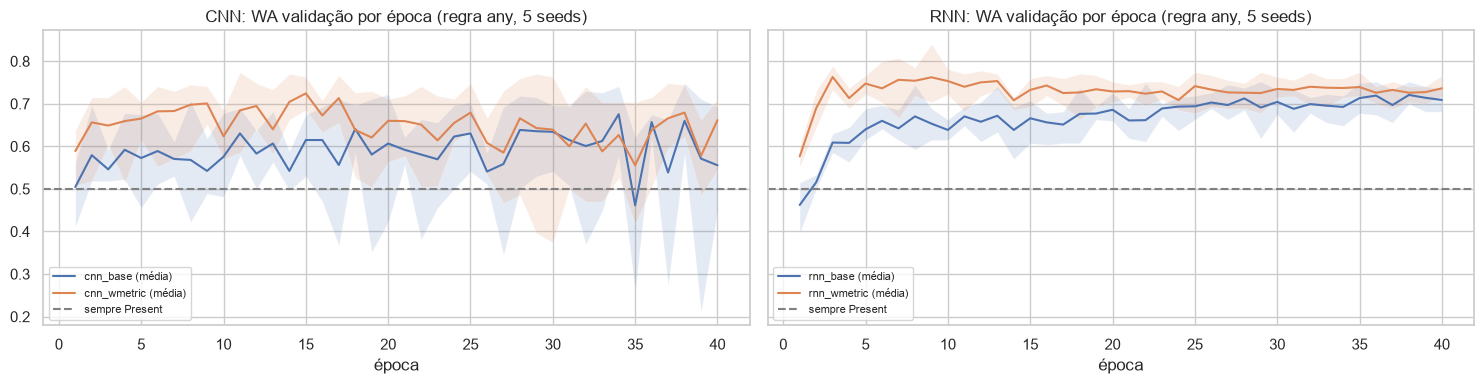

exp,cnn_base,cnn_wmetric,rnn_base,rnn_wmetric
seed,,,,
1,0.722,0.759,0.752,0.767
2,0.737,0.767,0.707,0.785
3,0.719,0.763,0.752,0.841
4,0.748,0.756,0.741,0.781
42,0.726,0.774,0.752,0.807


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, model in zip(axes, ["cnn", "rnn"]):
    for exp in [e for e in EXPS if e.startswith(model)]:
        c = curves[(curves["exp"] == exp) & (curves["rule"] == "any")].groupby("epoch")["wa"]
        ax.plot(c.mean().index, c.mean(), label=f"{exp} (média)")
        ax.fill_between(c.mean().index, c.min(), c.max(), alpha=0.15)
    ax.axhline(0.499, color="gray", ls="--", label="sempre Present")
    ax.set_title(f"{model.upper()}: WA validação por época (regra any, 5 seeds)"); ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "seeds_curvas_wa.png", dpi=120); plt.show()

# A melhor época de cada seed, e quanto varia de seed para seed
best = curves[curves["rule"] == "any"].loc[lambda d: d.groupby(["exp", "seed"])["wa"].idxmax()]
best.pivot(index="seed", columns="exp", values="wa").round(3).style.format("{:.3f}")

## 3. Avaliação justa dos critérios e das regras

**Problema:** se a época é escolhida pela WA da validação e depois reportamos essa mesma WA, o número é **otimista**:
escolhemos o pico de uma curva ruidosa (é o caso do 0.759 da `cnn_baseline`).

**Solução, sem tocar no teste:** dividir os 142 pacientes da validação em duas metades (estratificadas por classe).
Escolhe-se a época com a metade A e mede-se a WA na metade B; depois ao contrário; faz-se a média. Repete-se com
20 divisões diferentes para não depender de uma divisão concreta. A WA "ingénua" (escolher e medir nos mesmos
pacientes) aparece ao lado para comparar.

In [5]:
def es_select(scores, patience=8):
    # época escolhida por early stopping: a melhor até parar (paragem: `patience` épocas sem melhorar)
    best, best_epoch = -np.inf, None
    for epoch, s in enumerate(scores, start=1):
        if s > best:
            best, best_epoch = s, epoch
        elif epoch - best_epoch >= patience:
            break
    return best_epoch

def criterion_scores(criterion, wa_sel, loss_sel):
    # séries por época (quanto maior, melhor) para cada critério
    if criterion == "es_wa":
        return wa_sel
    if criterion == "es_wa3":
        return wa_sel.rolling(3, min_periods=1).mean()
    return -loss_sel

CRITERIA = ["es_wa", "es_wa3", "es_loss"]

def evaluate(sel_patients, eval_patients):
    # para cada (exp, seed, rule, criterion): época escolhida com sel_patients, WA medida em eval_patients
    wa_sel, wa_eval = wa_by_epoch(sel_patients), wa_by_epoch(eval_patients)
    loss_sel = loss_by_epoch(sel_patients)
    out = []
    for (exp, seed, rule), s in wa_sel.groupby(level=["exp", "seed", "rule"]):
        s = s.droplevel(["exp", "seed", "rule"])
        l = loss_sel.loc[(exp, seed)]
        for crit in CRITERIA:
            epoch = es_select(criterion_scores(crit, s, l).to_numpy())
            out.append({"exp": exp, "seed": seed, "rule": rule, "criterion": crit, "epoch": epoch,
                        "wa": wa_eval.loc[(exp, seed, rule, epoch)]})
    return pd.DataFrame(out)

naive = evaluate(None, None)

honest = []
for rep in range(20):
    skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=rep)
    for a, b in skf.split(patients, patients["murmur"]):
        honest.append(evaluate(patients.loc[a, "patient_id"], patients.loc[b, "patient_id"]).assign(rep=rep))
honest = pd.concat(honest).groupby(["exp", "seed", "rule", "criterion"], as_index=False)["wa"].mean()
print("feito")

feito


In [6]:
def summary(df):
    # média ± desvio entre seeds
    g = df.groupby(["exp", "rule", "criterion"])["wa"]
    return (g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)).unstack("criterion")[CRITERIA]

table = pd.concat({"WA justa (escolher numa metade, medir na outra)": summary(honest),
                   "WA ingénua (escolher e medir nos mesmos pacientes)": summary(naive)}, axis=1)
table.to_csv(RESULTS / "seeds_criterios_regras.csv")
table

WA justa (escolher numa metade, medir na outra)  \
criterion                                                  es_wa   
exp         rule                                                   
cnn_base    any                                    0.657 ± 0.014   
            half                                   0.677 ± 0.031   
            mean                                   0.703 ± 0.023   
cnn_wmetric any                                    0.707 ± 0.013   
            half                                   0.712 ± 0.013   
            mean                                   0.729 ± 0.012   
rnn_base    any                                     0.687 ± 0.03   
            half                                   0.723 ± 0.035   
            mean                                   0.718 ± 0.014   
rnn_wmetric any                                    0.768 ± 0.044   
            half                                    0.77 ± 0.037   
            mean                                   0.753 ± 0.028   

                                                \
criterion                es_wa3        es_loss   
exp         rule                                 
cnn_base    any   0.616 ± 0.031   0.591 ± 0.03   
            half  0.651 ± 0.021   0.645 ± 0.03   
            mean   0.682 ± 0.04  0.655 ± 0.025   
cnn_wmetric any   0.708 ± 0.012  0.719 ± 0.027   
            half  0.709 ± 0.015  0.721 ± 0.027   
            mean  0.727 ± 0.014  0.744 ± 0.027   
rnn_base    any   0.674 ± 0.014  0.656 ± 0.022   
            half  0.712 ± 0.014  0.708 ± 0.019   
            mean  0.716 ± 0.018  0.689 ± 0.014   
rnn_wmetric any   0.749 ± 0.031  0.728 ± 0.015   
            half   0.75 ± 0.019   0.735 ± 0.02   
            mean  0.746 ± 0.014   0.76 ± 0.023   

                 WA ingénua (escolher e medir nos mesmos pacientes)  \
criterion                                                     es_wa   
exp         rule                                                      
cnn_base    any                                         0.69 ± 0.03   
            half                                      0.729 ± 0.013   
            mean                                      0.736 ± 0.029   
cnn_wmetric any                                       0.755 ± 0.014   
            half                                      0.764 ± 0.018   
            mean                                      0.773 ± 0.017   
rnn_base    any                                       0.718 ± 0.024   
            half                                      0.763 ± 0.023   
            mean                                      0.747 ± 0.021   
rnn_wmetric any                                       0.796 ± 0.029   
            half                                      0.803 ± 0.023   
            mean                                      0.787 ± 0.019   

                                                
criterion                es_wa3        es_loss  
exp         rule                                
cnn_base    any   0.636 ± 0.034  0.588 ± 0.047  
            half   0.68 ± 0.029  0.656 ± 0.049  
            mean  0.704 ± 0.041  0.661 ± 0.044  
cnn_wmetric any   0.724 ± 0.038  0.733 ± 0.031  
            half   0.705 ± 0.03  0.735 ± 0.031  
            mean  0.742 ± 0.028  0.753 ± 0.044  
rnn_base    any   0.723 ± 0.026  0.653 ± 0.024  
            half  0.737 ± 0.041  0.707 ± 0.016  
            mean  0.733 ± 0.017  0.687 ± 0.027  
rnn_wmetric any   0.765 ± 0.032  0.714 ± 0.018  
            half  0.772 ± 0.026  0.724 ± 0.027  
            mean   0.759 ± 0.02   0.772 ± 0.04

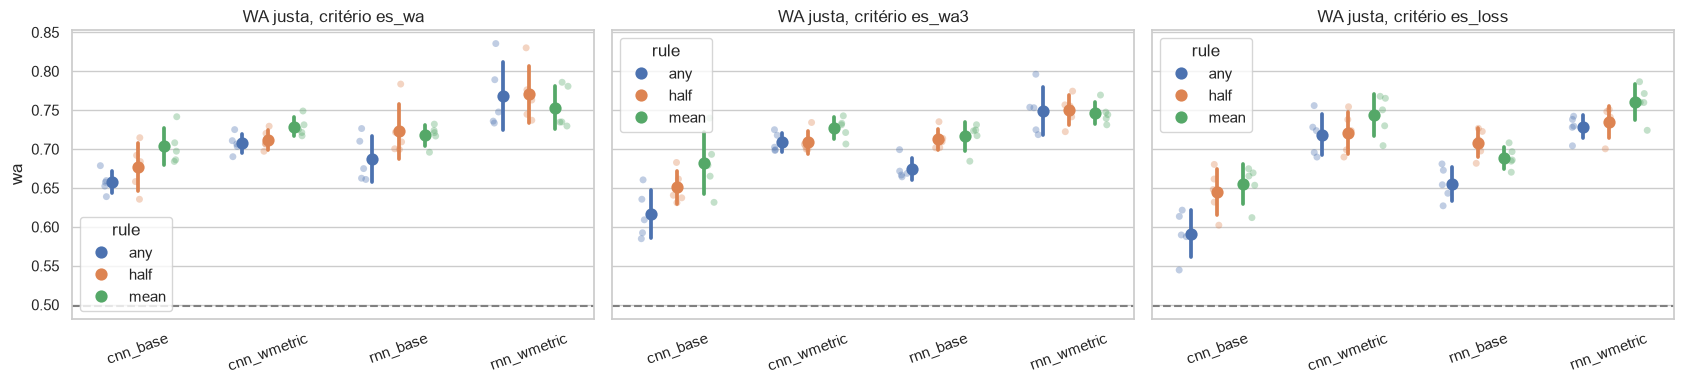

In [7]:
# Visualmente: WA justa por experiência e regra (critério es_wa3), cada ponto é uma seed
fig, axes = plt.subplots(1, len(CRITERIA), figsize=(17, 4), sharey=True)
for ax, crit in zip(axes, CRITERIA):
    d = honest[honest["criterion"] == crit]
    sns.pointplot(d, x="exp", y="wa", hue="rule", dodge=0.4, errorbar="sd", linestyle="none", ax=ax, order=EXPS)
    sns.stripplot(d, x="exp", y="wa", hue="rule", dodge=True, alpha=0.35, legend=False, ax=ax, order=EXPS)
    ax.axhline(0.499, color="gray", ls="--"); ax.set_title(f"WA justa, critério {crit}"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(RESULTS / "seeds_wa_justa.png", dpi=120); plt.show()

## 4. Onde estão os erros: matrizes de confusão (somadas nas 5 seeds)

Na época escolhida por `es_wa3` (com toda a validação). Linhas = previsto, colunas = verdadeiro, como no guião.
Cada matriz soma 5 × 142 = 710 pacientes.

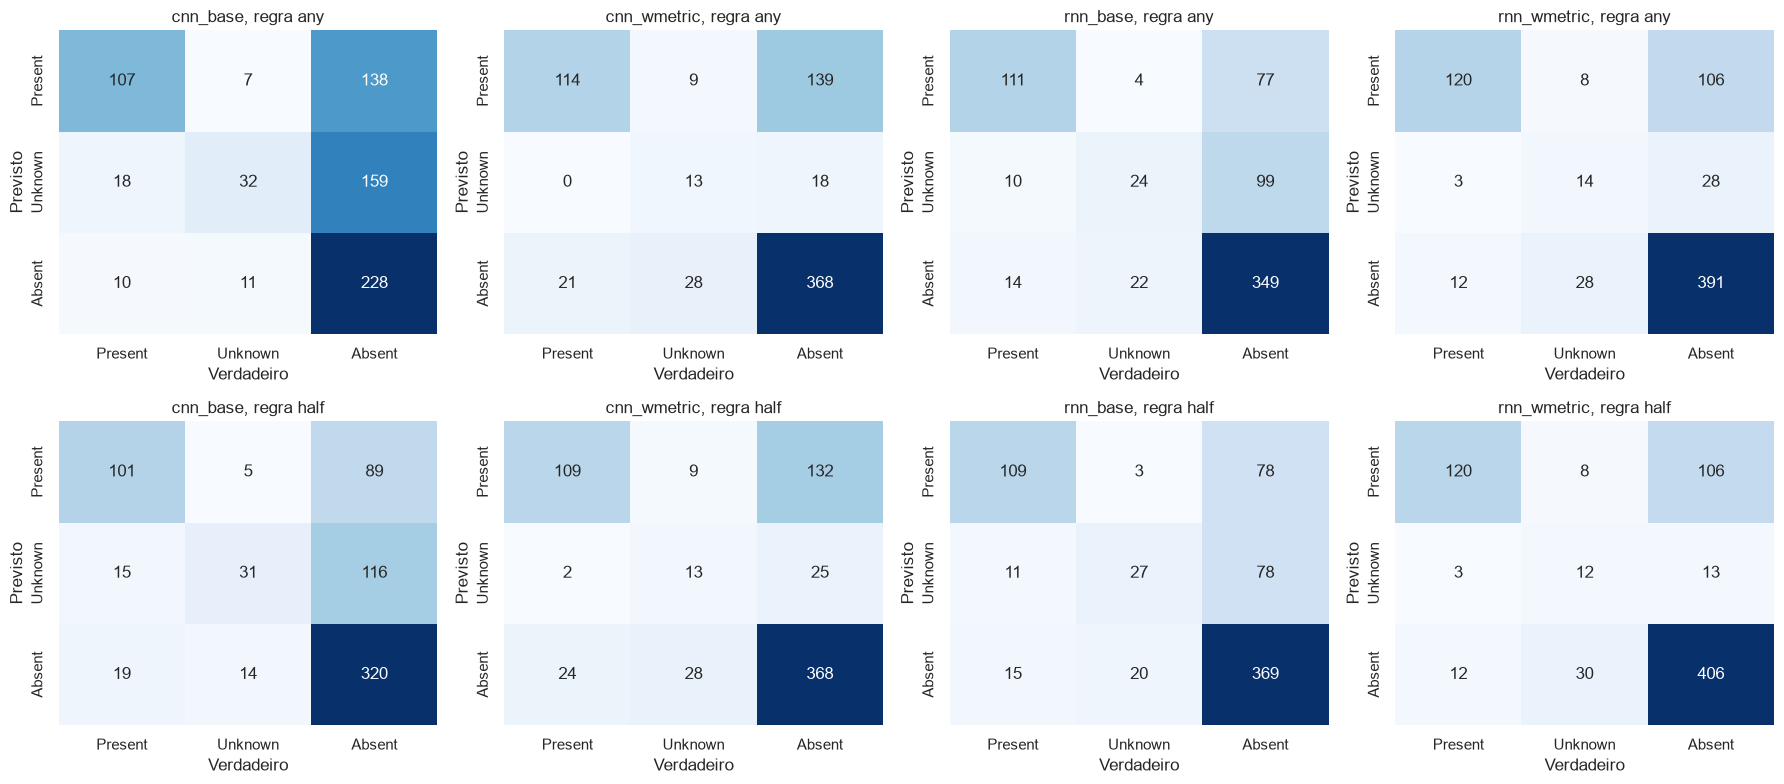

In [8]:
def summed_cm(exp, rule, criterion="es_wa3"):
    cm = 0
    for seed in SEEDS:
        epoch = naive.query("exp == @exp and seed == @seed and rule == @rule and criterion == @criterion")["epoch"].item()
        d = preds.query("exp == @exp and seed == @seed and rule == @rule and epoch == @epoch")
        cm = cm + confusion_matrix(d["murmur"], d["pred"])
    return cm

combos = [(e, r) for e in EXPS for r in ["any", "half"]]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (exp, rule) in zip(axes.T.flat, combos):
    sns.heatmap(summed_cm(exp, rule), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{exp}, regra {rule}")
plt.tight_layout(); plt.savefig(RESULTS / "seeds_matrizes.png", dpi=120); plt.show()

## 5. Conclusões

Execução de **26/11/2026** na GPU (RTX 5060): 20 corridas × 40 épocas, ~2.2 min por corrida da CNN e ~0.7 min da RNN.
Tabela completa em `results/seeds_criterios_regras.csv`; figuras `results/seeds_*.png`.

**WA justa** (época escolhida numa metade dos pacientes da validação, WA medida na outra; média ± desvio das 5 seeds):

| | `any` + `es_wa` (o procedimento original) | melhor combinação |
|---|---|---|
| `cnn_base` | 0.657 ± 0.014 | 0.703 ± 0.023 (`mean` + `es_wa`) |
| `cnn_wmetric` | 0.707 ± 0.013 | 0.744 ± 0.027 (`mean` + `es_loss`) |
| `rnn_base` | 0.687 ± 0.030 | 0.723 ± 0.035 (`half` + `es_wa`) |
| `rnn_wmetric` | **0.768 ± 0.044** | **0.770 ± 0.037** (`half` + `es_wa`) |

1. **Os números de uma só seed eram otimistas.** A WA "ingénua" (escolher a época e medir nos mesmos pacientes) fica
   0.03–0.05 acima da justa. O 0.759 da `cnn_baseline` (notebook 03) corresponde, com 5 seeds e avaliação justa,
   a ~0.66 com o mesmo procedimento.
2. **Pesos de classe iguais aos da métrica (5/3/1) são a melhoria mais clara**, nos dois modelos e com qualquer regra:
   +0.05 na CNN e +0.08 na RNN (procedimento original), bem acima do desvio entre seeds (0.01–0.04).
   Nas matrizes vê-se porquê: com os pesos equilibrados o *Unknown* tinha o maior peso (6.94) e a rede dava
   *Unknown* a muitos *Absent* (159 de 525 na CNN, 99 na RNN, somando as 5 seeds); com os pesos da métrica passam
   a 18–28. O preço é acertar menos *Unknown* (12–14 de 50, contra 24–32), que vale 3 e não 5.
3. **A regra de agregação conta sobretudo com os pesos equilibrados**: `half`/`mean` corrigem parte dos *Absent*
   dados como *Unknown* (+0.02 a +0.05). Com os pesos da métrica esse erro já quase não existe e as regras ficam a
   ≤ 0.02 umas das outras (dentro do ruído).
4. **O critério da época** (`es_wa`, `es_wa3`, `es_loss`) muda pouco e nenhum ganha sempre; diferenças dentro de 1 desvio.
5. **A RNN passa à frente da CNN.** Na corrida em CPU (notebook 04) a RNN parou na época 12 com 0.693; aqui, com 40
   épocas e várias seeds, é o melhor modelo. A curva da RNN também é **muito mais estável** do que a da CNN
   (secção 2: a CNN oscila 0.2–0.3 entre épocas seguidas; a RNN quase não oscila).

**Decisões para as experiências seguintes (27/11):**
- Pesos de classe **iguais aos da métrica** passam a ser o padrão nos dois modelos.
- Uma configuração **comum aos dois modelos**, para a comparação CNN vs. RNN ser justa e não escolhermos 9 combinações
  à medida de cada um: regra `mean` (sem parâmetros, a mais simples) e época pela **loss da validação**
  (usa todas as janelas, menos sensível a um paciente). Com ela: CNN 0.744 ± 0.027, RNN 0.760 ± 0.023.
  As alternativas ficam a ≤ 0.01, por isso a escolha não depende da sorte.
- **O teste continua por usar.**